**Notebook to investigate interesting passes from pipeline output.**

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pyspedas
from pyspedas import get_data
from lunarmag import analyse_pass

REPO = Path.cwd().resolve().parent
RAW = REPO / 'data' / 'raw'
FIG = REPO / 'figures' / 'events'
FIG.mkdir(parents=True, exist_ok=True)

25-Nov-26 16:57:13: /Users/yulun/artemis-lunar-plasma/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Load pass list to load periapsis time of each pass:

In [2]:
passes = pd.read_csv(RAW / 'thb_2012_2025_all_passes.csv')
passes['pass_id'] = passes['year'].astype(str) + '-' + passes['pass_number'].astype(str).str.zfill(2)
passes['t_peri'] = pd.to_datetime(passes['lowest_minute_utc']).dt.strftime('%Y-%m-%d/%H:%M:%S')

Write function to output Sawyer style figure:

In [15]:
def sawyer_overview(pass_id, window=600, probe='b', monitor='c'):
    """Sawyer et al. (2023)-style overview for one pass, on a UT time axis."""
    row = passes.loc[passes['pass_id'] == pass_id].iloc[0]
    r = analyse_pass(row['t_peri'], no_update=True)
    s = r['summary']
    tp, tau = s['t_peri'], s['bg_shift']
    tr = [pyspedas.time_string(tp - window), pyspedas.time_string(tp + window)]
    pyspedas.projects.themis.esa(probe=probe, trange=tr, level='l2', time_clip=True)
    ut = lambda t: pd.to_datetime(np.asarray(t), unit='s')

    labels = ['Altitude\n(km)', 'B THC\n(nT)', 'B THB\n(nT)', '|ΔB|, |SVM|\n(nT)',
              'Ion E\n(eV/q)', 'Electron E\n(eV)', 'Te\n(eV)', 'n\n(cm⁻³)', 'Vi\n(km/s)']
    fig = plt.figure(figsize=(11, 18))
    gs = GridSpec(len(labels), 2, width_ratios=[1, 0.015], hspace=0.07, wspace=0.02, figure=fig)
    axs = [fig.add_subplot(gs[i, 0]) for i in range(len(labels))]
    for ax in axs[1:]:
        ax.sharex(axs[0])
    SPEC = (4, 5)                                                  # spectrogram rows

    # (a) altitude
    axs[0].plot(ut(r['t']), r['alt'], 'k', lw=1)

    # (b), (c) raw field; THC also shifted onto THB's clock (dashed) in the THB panel
    cols = {'x': 'tab:blue', 'y': 'tab:green', 'z': 'tab:red'}
    c, b = get_data(f'th{monitor}_fgs_gse'), get_data(f'th{probe}_fgs_gse')
    lim = max(np.nanmax(np.abs(f.y[(f.times > tp - window) & (f.times < tp + window)])) for f in (c, b))
    for ax, f in ((axs[1], c), (axs[2], b)):
        for i, k in enumerate('xyz'):
            ax.plot(ut(f.times), f.y[:, i], color=cols[k], lw=0.8, label=f'B{k}')
        ax.plot(ut(f.times), np.linalg.norm(f.y, axis=1), 'k', lw=0.8, label='|B|')
        ax.axhline(0, color='k', ls='--', lw=0.5); ax.set_ylim(-1.1 * lim, 1.1 * lim)
    axs[2].plot(ut(c.times + tau), np.linalg.norm(c.y, axis=1), 'k--', lw=0.7, label=f'|B| THC, shifted {tau:+.0f} s')
    axs[2].plot(ut(c.times + tau), c.y[:, 2], '--', color=cols['z'], lw=0.7, label='Bz THC, shifted')
    axs[2].legend(fontsize=7, ncol=3, loc='lower right')

    # lunar effect against the predicted crust
    axs[3].plot(ut(r['t']), np.linalg.norm(r['dB_enr'], axis=1), 'k', lw=0.8, label='|ΔB|')
    axs[3].plot(ut(r['t']), np.linalg.norm(r['svm_enr'], axis=1), 'C1', lw=1.2, label='|SVM|')
    axs[3].legend(fontsize=7)

    # (d), (e) energy spectrograms
    def spec(i, name, vmin, vmax):
        d = get_data(name)
        E = d.v if d.v.ndim == 2 else np.tile(d.v, (len(d.times), 1))
        good = np.isfinite(E).all(axis=0)
        pc = axs[i].pcolormesh(ut(d.times), E[0, good], d.y[:, good].T,
                               norm=LogNorm(vmin, vmax), shading='auto', cmap='turbo')
        axs[i].set_yscale('log')
        fig.colorbar(pc, cax=fig.add_subplot(gs[i, 1]), label='eflux')
    spec(4, f'th{probe}_peir_en_eflux', 1e4, 1e8)
    spec(5, f'th{probe}_peer_en_eflux', 1e4, 1e9)

    # electron temperature (scalar: the three magt3 columns are identical)
    T = get_data(f'th{probe}_peer_magt3')
    if T is not None:
        axs[6].plot(ut(T.times), T.y[:, 0], 'k', lw=0.8)

    # densities: ions and electrons
    for name, colour, lab in ((f'th{probe}_peir_density', 'k', 'ions'),
                              (f'th{probe}_peer_density', 'C3', 'electrons')):
        d = get_data(name)
        if d is not None:
            axs[7].plot(ut(d.times), d.y, color=colour, lw=0.8, label=lab)
    axs[7].legend(fontsize=7)

    # ion velocity
    V = get_data(f'th{probe}_peir_velocity_gse')
    for i, k in enumerate('xyz'):
        axs[8].plot(ut(V.times), V.y[:, i], color=cols[k], lw=0.8, label=f'V{k}')
    axs[8].legend(fontsize=7, ncol=3)

    # decoration: crust shaded on line plots, bounded by white lines on spectrograms
    crust = r['use'] & (np.linalg.norm(r['svm_enr'], axis=1) > 1.0)
    t_c0, t_c1 = ut(r['t'][crust][[0, -1]]) if crust.any() else (None, None)
    for i, (ax, lab) in enumerate(zip(axs, labels)):
        ax.set_ylabel(lab, fontsize=9)
        ax.axvline(ut([tp])[0], color='k', ls='--', lw=0.7)
        if i in SPEC:
            if t_c0 is not None:
                ax.axvline(t_c0, color='w', lw=0.9); ax.axvline(t_c1, color='w', lw=0.9)
        else:
            ax.fill_between(ut(r['t']), 0, 1, where=crust, color='C2', alpha=0.15,
                            transform=ax.get_xaxis_transform())
    for ax in axs[:-1]:
        ax.tick_params(labelbottom=False)
    axs[-1].set_xlim(ut([tp - window, tp + window]))
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
    axs[-1].set_xlabel(f"UT, {pd.to_datetime(tp, unit='s'):%Y %b %d}")
    fig.suptitle(f'{pass_id}: ARTEMIS THB event overview', y=0.9)
    return fig, r

25-Nov-26 17:14:24: Local files found: ['themis_data/thb/l2/fgm/2014/thb_l2_fgm_20140526_v01.cdf']
25-Nov-26 17:14:24: Local files found: ['themis_data/thc/l2/fgm/2014/thc_l2_fgm_20140526_v01.cdf']
25-Nov-26 17:14:24: time_clip: thc_fgh_btotal has no data in requested range
25-Nov-26 17:14:24: time_clip: thc_fgh_gse has no data in requested range
25-Nov-26 17:14:24: time_clip: thc_fgh_gsm has no data in requested range
25-Nov-26 17:14:25: time_clip: thc_fgh_dsl has no data in requested range
25-Nov-26 17:14:25: time_clip: thc_fgh_ssl has no data in requested range
25-Nov-26 17:14:25: Eclipse correction status for probe ['b', 'c']:
25-Nov-26 17:14:25: Eclipse 1 of 1: start: 2014-05-26 19:01:01.916393  end: 2014-05-26 20:10:50.537181 status: in shadow, fully corrected
25-Nov-26 17:14:25: Applying spin fit eclipse corrections to thb_fgs_gse
25-Nov-26 17:14:25: tinterpol (linear) was applied to: thb_spinras_corrected_hires
25-Nov-26 17:14:25: tinterpol (linear) was applied to: thb_spindec_

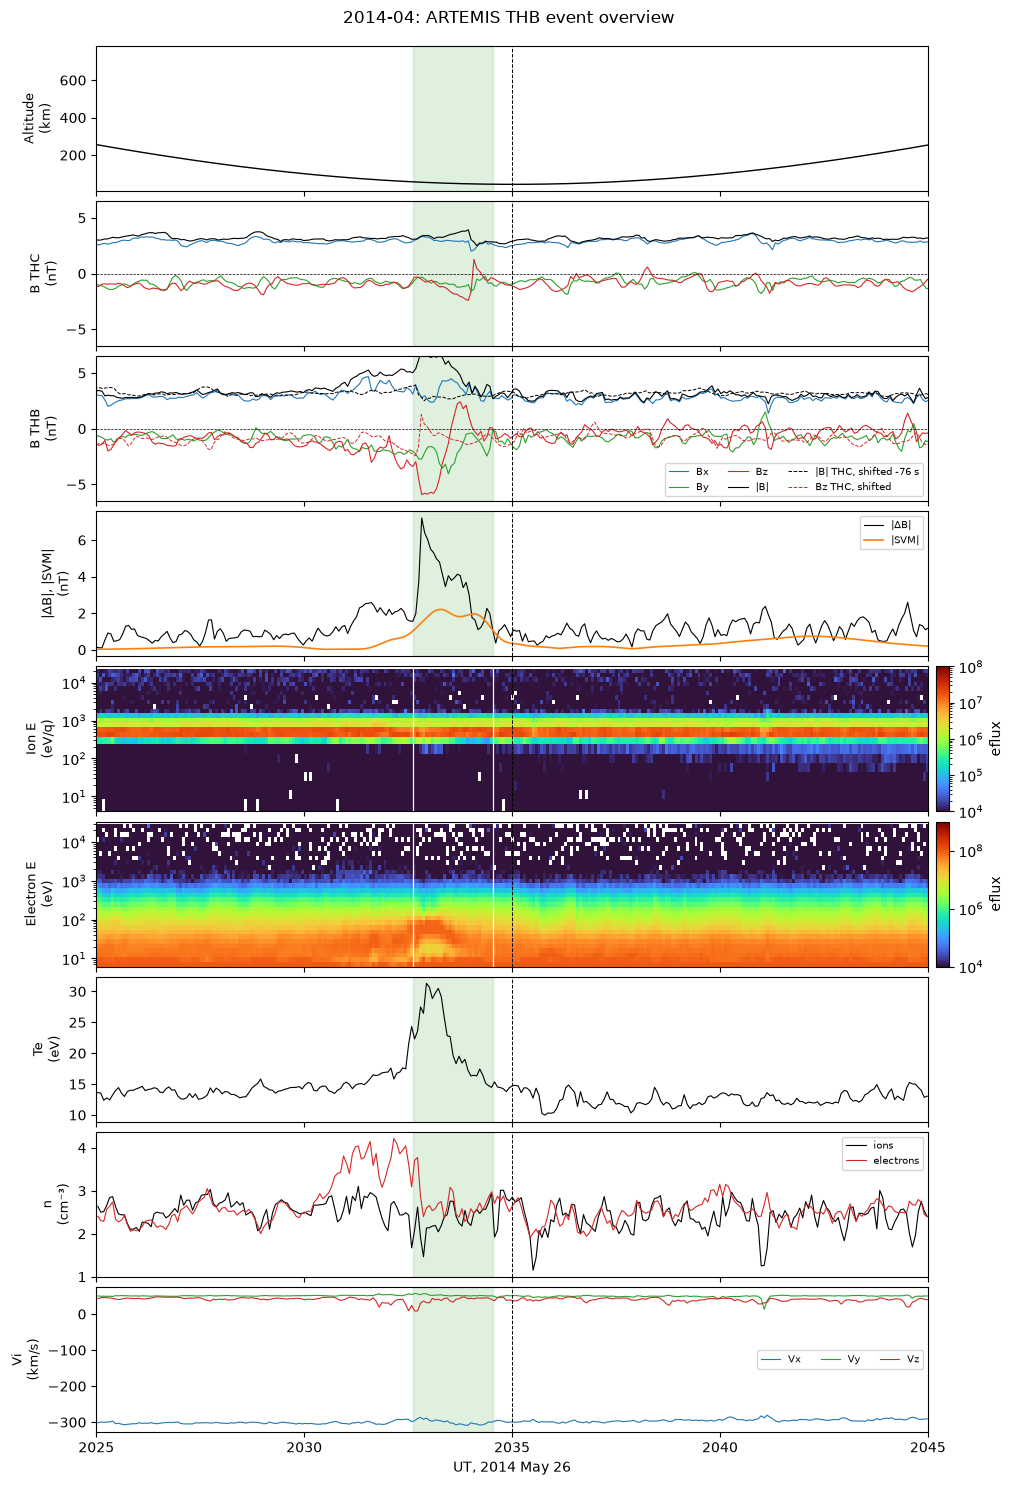

In [16]:
fig, r = sawyer_overview('2014-04')
fig.savefig(FIG / '2014-04_overview.png', dpi=150, bbox_inches='tight')